# Day 21: CNN step by step

We follow **one small picture of a "1"** through the whole network.
Then we do the **same steps** on real handwritten digits.

**The map** (same as the slides):

| Image | → Conv | → ReLU | → Pool | → Flatten | → Dense | → Softmax | → Answer |
|---|---|---|---|---|---|---|---|
| 6×6 | 4×4 | 4×4 | 2×2 | 4 numbers | 3 scores | 3 chances | "1" |

- **Part 1 (find patterns):** Conv → ReLU → Pool
- **Part 2 (decide):** Flatten → Dense → Softmax

### New words today

| Word | Meaning |
|---|---|
| **Pixel** | One small square of a picture. One number. |
| **Filter (kernel)** | A small grid (3×3) that looks for one pattern. |
| **Convolution** | Place the filter, multiply, add. Then slide. |
| **Feature map** | The output of convolution: where the pattern was found. |
| **ReLU** | Negative numbers become 0. |
| **Max pooling** | Keep the biggest number of each 2×2 block. |
| **Flatten** | Grid → one row. |
| **Dense** | Every input goes to every neuron. Each neuron gives a score. |
| **Softmax** | Scores → chances that add up to 100%. |
| **Accuracy** | Correct answers ÷ all answers. |

In [34]:
import numpy as np                                     # arrays of numbers
import matplotlib.pyplot as plt                        # draw pictures and charts
import torch                                           # PyTorch: tensors + training
from torch import nn                                   # nn = "neural network": layers, ReLU, loss functions
from sklearn.model_selection import train_test_split   # split data into train / validation / test
from sklearn.datasets import load_digits               # the handwritten digits pictures

def show(grid, title):                                 # draw a small grid with its numbers on it
    grid = np.array(grid)
    plt.imshow(grid, cmap="gray_r")                    # big number = dark (ink)
    for r in range(grid.shape[0]):
        for c in range(grid.shape[1]):
            plt.text(c, r, f"{grid[r, c]:g}", ha="center", va="center", color="tab:orange")
    plt.title(title)
    plt.axis("off")
    plt.show()

---
# Class Problem 1: one picture of a "1"

We do every step **by hand first**, then with **PyTorch**. The numbers must match the slides.

## Step 1: The image (6×6)

- A picture is a grid of numbers.
- **0 = no ink**, **9 = ink**.
- Columns 2 and 3 have ink: a vertical stroke. That is a **"1"**.

torch.Size([6, 6])


C:\Users\Muzammil Ansari\AppData\Local\Temp\ipykernel_664\2152282032.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  grid = np.array(grid)


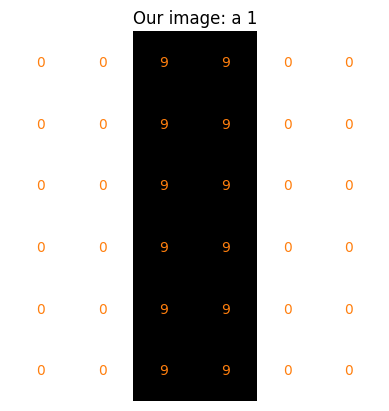

In [35]:
image = torch.tensor([[0, 0, 9, 9, 0, 0],
                      [0, 0, 9, 9, 0, 0],
                      [0, 0, 9, 9, 0, 0],
                      [0, 0, 9, 9, 0, 0],
                      [0, 0, 9, 9, 0, 0],
                      [0, 0, 9, 9, 0, 0]], dtype=torch.float32)

print(image.shape)          # 6 rows, 6 columns
show(image, "Our image: a 1")

**✏️ Quick Check 1:** How many numbers are in the image? Use `image.numel()` (numel = number of elements).

In [36]:
# your code here

**Answer:**

In [37]:
print(image.numel())        # 6 × 6 = 36

36


## Step 2: The filter (3×3)

- Left column **−1**, middle **0**, right column **+1**.
- Ink on the right → big **+** number. Ink on the left → big **−** number.
- **We choose the size (3×3). The model learns the 9 numbers.** Today we write them ourselves, only to understand.

C:\Users\Muzammil Ansari\AppData\Local\Temp\ipykernel_664\2152282032.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  grid = np.array(grid)


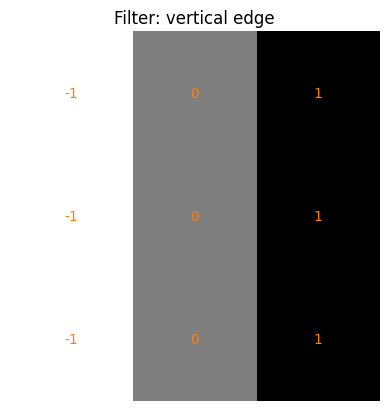

In [38]:
filter_v = torch.tensor([[-1, 0, 1],
                         [-1, 0, 1],
                         [-1, 0, 1]], dtype=torch.float32)   # v = vertical edge
show(filter_v, "Filter: vertical edge")

**✏️ Quick Check 2:** Make `filter_h`, a **horizontal** edge filter: top row −1, middle row 0, bottom row +1.

In [39]:
# your code here

**Answer:**

In [40]:
filter_h = torch.tensor([[-1, -1, -1],
                         [ 0,  0,  0],
                         [ 1,  1,  1]], dtype=torch.float32)
print(filter_h)

tensor([[-1., -1., -1.],
        [ 0.,  0.,  0.],
        [ 1.,  1.,  1.]])


## Step 3: Convolution by hand

1. **Place** the filter on a 3×3 window.
2. **Multiply** matching numbers.
3. **Add** them all → one number.

First, one window: rows 0–2, columns 1–3.

In [41]:
window = image[0:3, 1:4]               # rows 0,1,2 and columns 1,2,3
print(window)
print(window * filter_v)               # 2. multiply matching numbers (-0 is just 0)
print((window * filter_v).sum())       # 3. add → 27

tensor([[0., 9., 9.],
        [0., 9., 9.],
        [0., 9., 9.]])
tensor([[-0., 0., 9.],
        [-0., 0., 9.],
        [-0., 0., 9.]])
tensor(27.)


Now **slide** the window over the whole image. Size of the output: **6 − 3 + 1 = 4**.

tensor([[ 27.,  27., -27., -27.],
        [ 27.,  27., -27., -27.],
        [ 27.,  27., -27., -27.],
        [ 27.,  27., -27., -27.]])


C:\Users\Muzammil Ansari\AppData\Local\Temp\ipykernel_664\2152282032.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  grid = np.array(grid)


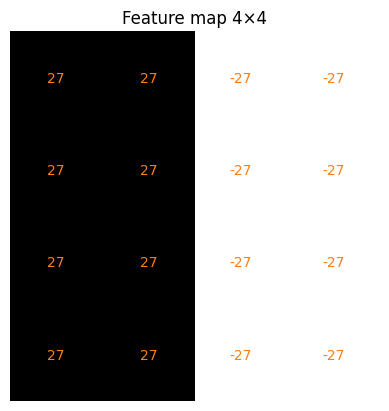

In [42]:
size = 6 - 3 + 1                                   # 4 windows across, 4 down
feature_map = torch.zeros(size, size)

for r in range(size):                              # slide down
    for c in range(size):                          # slide right
        window = image[r:r+3, c:c+3]               # 1. place
        feature_map[r, c] = (window * filter_v).sum()   # 2. multiply + 3. add

print(feature_map)
show(feature_map, "Feature map 4×4")

- **+27** = ink starts (left edge of the stroke).
- **−27** = ink ends (right edge of the stroke).

**✏️ Quick Check 3:** Take the window at rows 0–2, **columns 2–4**. Multiply with `filter_v` and add. What do you get?

In [43]:
# your code here

**Answer:**

In [44]:
window = image[0:3, 2:5]
print((window * filter_v).sum())       # −27: ink ends here

tensor(-27.)


## Step 4: The same with PyTorch: `nn.Conv2d`

- PyTorch wants the shape **(pictures, channels, height, width)**.
- We have 1 picture, 1 channel (gray) → `(1, 1, 6, 6)`.
- `nn.Conv2d(1, 1, 3)` = 1 channel in, 1 filter, size 3×3.
- We put **our** filter numbers inside (normally they are learned).
- You will see `grad_fn=...` in the output. PyTorch remembers the steps for training. Ignore it.

In [45]:
x = image.reshape(1, 1, 6, 6)                       # (pictures, channels, height, width)

conv = nn.Conv2d(1, 1, 3, bias=False)               # 1 channel in, 1 filter, 3×3

with torch.no_grad():                               # we set the numbers ourselves, no training
    conv.weight[:] = filter_v.reshape(1, 1, 3, 3)

out_conv = conv(x)
print(out_conv.shape)                               # (1, 1, 4, 4) → 4×4
print(out_conv[0, 0])                               # same as our loop: 27, 27, −27, −27

torch.Size([1, 1, 4, 4])
tensor([[ 27.,  27., -27., -27.],
        [ 27.,  27., -27., -27.],
        [ 27.,  27., -27., -27.],
        [ 27.,  27., -27., -27.]], grad_fn=<SelectBackward0>)


## Step 5: ReLU

- Negative → **0**. Positive → stays the same.
- The size does **not** change: 4×4 → 4×4.

In [46]:
out_relu = nn.ReLU()(out_conv)
print(out_relu[0, 0])                               # −27 became 0
# show(out_relu[0, 0], "Feature map after ReLU")

tensor([[27., 27.,  0.,  0.],
        [27., 27.,  0.,  0.],
        [27., 27.,  0.,  0.],
        [27., 27.,  0.,  0.]], grad_fn=<SelectBackward0>)


**✏️ Quick Check 4:** Apply ReLU to `torch.tensor([-5., 3., -2., 8.])`. Guess first, then run.

In [47]:
# your code here

**Answer:**

In [48]:
print(nn.ReLU()(torch.tensor([-5., 3., -2., 8.])))   # [0, 3, 0, 8]

tensor([0., 3., 0., 8.])


## Step 6: Max pooling (2×2)

- Cut the map into 2×2 blocks. Keep the **biggest** number of each block.
- Size: **4 ÷ 2 = 2** → 2×2.
- **We choose** the pool size (2×2). There is nothing to learn.

torch.Size([1, 1, 2, 2])
tensor([[27.,  0.],
        [27.,  0.]], grad_fn=<SelectBackward0>)


C:\Users\Muzammil Ansari\AppData\Local\Temp\ipykernel_664\2152282032.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  grid = np.array(grid)


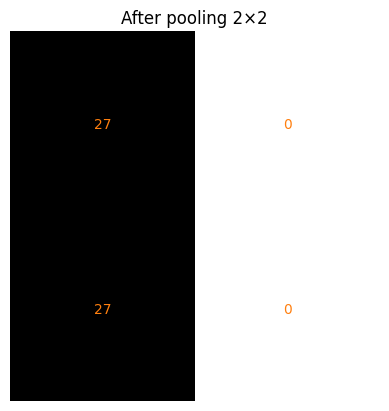

In [49]:
out_pool = nn.MaxPool2d(2)(out_relu)
print(out_pool.shape)                               # (1, 1, 2, 2)
print(out_pool[0, 0])                               # 27 0 / 27 0
show(out_pool[0, 0].detach(), "After pooling 2×2")

It still says: **edge on the left, nothing on the right**, with 4 numbers instead of 16.

**✏️ Quick Check 5:** What size comes out if we pool a **6×6** map? Try `nn.MaxPool2d(2)(torch.zeros(1, 1, 6, 6)).shape`.

In [50]:
# your code here

**Answer:**

In [51]:
print(nn.MaxPool2d(2)(torch.zeros(1, 1, 6, 6)).shape)   # 6 ÷ 2 = 3 → 3×3

torch.Size([1, 1, 3, 3])


## Step 7: Flatten (Part 2 starts)

- Read the grid **row by row** → one row.
- 2 × 2 = **4 numbers**. Nothing is lost, nothing is learned.

In [52]:
out_flat = nn.Flatten()(out_pool)
print(out_flat)                                     # [27, 0, 27, 0]
print(out_flat.shape)                               # (1, 4)

tensor([[27.,  0., 27.,  0.]], grad_fn=<ViewBackward0>)
torch.Size([1, 4])


## Step 8: Dense (3 neurons: "1", "7", "0")

- Each neuron: **(each input × its weight), all added, + bias** = one score.
- `nn.Linear(4, 3)` = 4 inputs, 3 neurons.
- The weights are normally **learned**. We use the slide numbers so the maths is easy.

In [53]:
dense = nn.Linear(4, 3)
with torch.no_grad():
    dense.weight[:] = torch.tensor([[0.05, 0,   0.05, 0  ],     # neuron "1"
                                    [0.02, 0,   0.02, 0  ],     # neuron "7"
                                    [0,    0.5, 0,    0.5]])    # neuron "0"
    dense.bias[:] = torch.tensor([-0.7, -0.08, 0])

scores = dense(out_flat)
print(scores)                                       # 2.0, 1.0, 0.0

tensor([[2.0000, 1.0000, 0.0000]], grad_fn=<AddmmBackward0>)


**✏️ Quick Check 6:** Work out the score of neuron "1" with plain Python: `27×0.05 + 0×0 + 27×0.05 + 0×0 − 0.7`.

In [54]:
# your code here

**Answer:**

In [55]:
print(27*0.05 + 0*0 + 27*0.05 + 0*0 - 0.7)          # 2.0

2.0


## Step 9: Softmax → answer

1. e to the power of each score.
2. Add them.
3. Divide each one by the total → chances that add up to 1.

In [56]:
e = torch.exp(scores)                               # step 1
print(e)                                            # 7.39, 2.72, 1.00
print(e.sum())                                      # step 2: 11.11
print(e / e.sum())                                  # step 3: 0.67, 0.24, 0.09

chances = torch.softmax(scores, dim=1)              # PyTorch does all 3 steps
print(chances)

classes = ["1", "7", "0"]
print("Answer:", classes[chances.argmax()])         # argmax = position of the biggest

tensor([[7.3891, 2.7183, 1.0000]], grad_fn=<ExpBackward0>)
tensor(11.1073, grad_fn=<SumBackward0>)
tensor([[0.6652, 0.2447, 0.0900]], grad_fn=<DivBackward0>)
tensor([[0.6652, 0.2447, 0.0900]], grad_fn=<SoftmaxBackward0>)
Answer: 1


**✏️ Quick Check 7:** Try `torch.sigmoid(scores)` instead. Do the 3 numbers add up to 1? Why is softmax better here?

In [57]:
# your code here

**Answer:**

In [58]:
s = torch.sigmoid(scores)
print(s, s.sum())     # 0.88, 0.73, 0.50 → 2.11. Sigmoid looks at each class alone.
                      # Softmax makes the classes share 100%: one picture = one digit.

tensor([[0.8808, 0.7311, 0.5000]], grad_fn=<SigmoidBackward0>) tensor(2.1119, grad_fn=<SumBackward0>)


## The whole toy network in one place

The same steps as one PyTorch model. The answer is the same.

In [59]:
toy_model = nn.Sequential(
    conv, 
    nn.ReLU(), 
    nn.MaxPool2d(2), 
    nn.Flatten(), 
    dense
)

scores = toy_model(image.reshape(1, 1, 6, 6))
print(scores)                                       # 2.0, 1.0, 0.0
print(torch.softmax(scores, dim=1))                 # 0.67, 0.24, 0.09 → "1"

tensor([[2.0000, 1.0000, 0.0000]], grad_fn=<AddmmBackward0>)
tensor([[0.6652, 0.2447, 0.0900]], grad_fn=<SoftmaxBackward0>)


---
# Class Problem 2: real handwritten digits

**Same steps, bigger pictures.** Now the filters are **learned**.

| Step | Our "1" | Real digits |
|---|---|---|
| Image | 6×6 | 8×8 |
| Conv | 1 filter (ours) | 16 filters (learned): 16 different pattern finders |
| Feature maps | 4×4 | 16 maps of 6×6 (8 − 3 + 1) |
| Pool 2×2 | 2×2 | 16 maps of 3×3 (6 ÷ 2) |
| Flatten | 4 | 16 × 3 × 3 = **144** |
| Dense | 3 scores | 32 neurons, then 10 scores |

## Step 1: Load the data

- 1797 pictures, each **8 × 8 = 64 pixels**. 0 = no ink, 16 = full ink.
- We divide by 16, so every pixel is from 0 to 1.
- ⚠️ This 16 is the **ink scale** of the pictures. It is **not** the 16 filters we use later.

(1797, 64) (1797,)


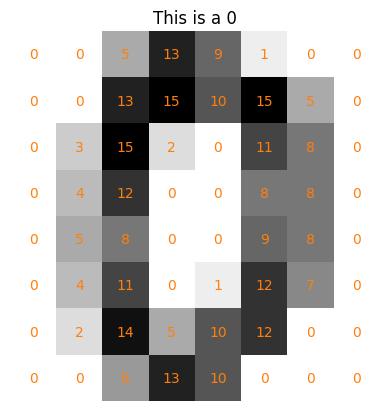

In [73]:
digits = load_digits()
X = digits.data / 16                                # pixels 0..16 → 0..1 (ink scale, not filters)
y = digits.target                                   # the real digit (0 to 9)
print(X.shape, y.shape)

show(digits.images[0], f"This is a {y[0]}")

## Step 2: Split (60 / 20 / 20)

Homework (train), mock exam (validation), final exam (test). Same as the digits example.

In [61]:
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=42)          # final exam (20%)

X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=42) # homework + mock exam

print("train:", len(X_train), " val:", len(X_val), " test:", len(X_test))

train: 1077  val: 360  test: 360


## Step 3: Make tensors as pictures

- A CNN needs pictures, not long rows: shape **(pictures, 1, 8, 8)**.
- Answers → whole numbers (`torch.long`) for `CrossEntropyLoss`.

In [62]:
def to_tensor(a, dtype=torch.float32):
    return torch.tensor(a, dtype=dtype)

def to_pictures(a):
    return to_tensor(a).reshape(-1, 1, 8, 8)        # -1 = "work out how many pictures"

X_train_t, X_val_t, X_test_t = to_pictures(X_train), to_pictures(X_val), to_pictures(X_test)
y_train_t, y_val_t = to_tensor(y_train, torch.long), to_tensor(y_val, torch.long)
print(X_train_t.shape)

torch.Size([1077, 1, 8, 8])


## Step 4: Build the CNN

- **Part 1:** `Conv2d(1, 16, 3)` → ReLU → `MaxPool2d(2)`
- **Part 2:** Flatten → `Linear(144, 32)` → ReLU → `Linear(32, 10)`
- **No softmax layer:** `CrossEntropyLoss` already does softmax inside.
- In PyTorch **we must type 144** (16 × 3 × 3). The size rules help us.

### Why 16 filters?

- **One filter finds one pattern.** Our "1" needed only one: a vertical edge.
- Real digits need **many patterns**: vertical lines (1), horizontal lines (top of 7), slanted lines (7), curves (0, 3, 8), corners (4).
- So we give the network **16 filters = 16 pattern finders**. Training decides what each one looks for.
- **16 is our choice** (a hyperparameter). Nobody calculates it.
- **Why not fewer?** 4 filters may miss some patterns.
- **Why not many more?** More filters = more numbers to learn, slower, and it can start to memorise. 8×8 pictures are small, so 16 is enough.
- People usually pick 8, 16, 32 or 64 (they double by habit).
- **We check it:** the Home Problem tries 32 filters and compares the accuracy.

In [63]:
class CNN(nn.Module):
    def __init__(self, n_filters, n_hidden, n_outputs):
        super().__init__()
        self.conv = nn.Conv2d(1, n_filters, 3)            # 8×8 → 6×6, one map per filter (16 filters → 16 maps)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2)                       # 6×6 → 3×3
        self.flatten = nn.Flatten()                       # n_filters × 3 × 3 numbers
        self.hidden = nn.Linear(n_filters * 3 * 3, n_hidden)
        self.output = nn.Linear(n_hidden, n_outputs)      # one score per digit

    def forward(self, x):
        x = self.pool(self.relu(self.conv(x)))            # Part 1: find patterns
        x = self.flatten(x)                               # Part 2: decide
        return self.output(self.relu(self.hidden(x)))

Follow **one picture** through the layers and print the shape after each one:

In [64]:
torch.manual_seed(42)                               # the same random start for everyone
model = CNN(n_filters=16, n_hidden=32, n_outputs=10)   # 16 filters = 16 pattern finders (our choice, enough for 8×8)

x = X_train_t[:1]                                   # one picture
print("image   ", x.shape)
x = model.conv(x);    print("conv    ", x.shape)    # 16 maps (one per filter), each 8 − 3 + 1 = 6
x = model.relu(x);    print("relu    ", x.shape)
x = model.pool(x);    print("pool    ", x.shape)    # 6 ÷ 2 = 3
x = model.flatten(x); print("flatten ", x.shape)    # 16 maps × 3 × 3 = 144

# each filter = 9 numbers + 1 bias → 16 filters × 10 = 160 numbers to learn
print("numbers to learn in conv:", sum(p.numel() for p in model.conv.parameters()))

image    torch.Size([1, 1, 8, 8])
conv     torch.Size([1, 16, 6, 6])
relu     torch.Size([1, 16, 6, 6])
pool     torch.Size([1, 16, 3, 3])
flatten  torch.Size([1, 144])
numbers to learn in conv: 160


**✏️ Quick Check 8:** If we use **32 filters**, what number must go in `nn.Linear(?, 32)`? Work it out, then check with `CNN(32, 32, 10).hidden`.

In [65]:
# your code here

**Answer:**

In [66]:
print(32 * 3 * 3)               # 288
print(CNN(32, 32, 10).hidden)   # Linear(in_features=288, ...)

288
Linear(in_features=288, out_features=32, bias=True)


## Step 5: Train

Same `Trainer` as the digits example: guess → loss → backprop → fix, again and again.

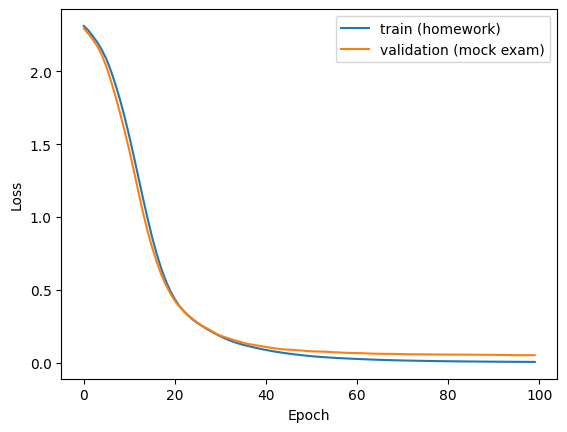

In [67]:
class Trainer:
    def __init__(self, model, loss_fn, lr):
        self.model = model
        self.loss_fn = loss_fn
        self.optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        self.train_losses, self.val_losses = [], []

    def fit(self, X_train, y_train, X_val, y_val, epochs):
        for epoch in range(epochs):
            loss = self.loss_fn(self.model(X_train), y_train)   # 1. guess + 2. how wrong
            self.optimizer.zero_grad()                          # 3. clear old blame
            loss.backward()                                     # 4. find blame (backprop)
            self.optimizer.step()                               # 5. fix (gradient descent)
            self.train_losses.append(loss.item())
            with torch.no_grad():                               # mock exam: check only
                self.val_losses.append(self.loss_fn(self.model(X_val), y_val).item())

    def predict(self, X):
        with torch.no_grad():
            return self.model(X)

    def plot(self):
        plt.plot(self.train_losses, label="train (homework)")
        plt.plot(self.val_losses, label="validation (mock exam)")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.show()


torch.manual_seed(42)
model = CNN(n_filters=16, n_hidden=32, n_outputs=10)   # 16 filters = 16 pattern finders (our choice, enough for 8×8)
trainer = Trainer(model, nn.CrossEntropyLoss(), lr=0.01)
trainer.fit(X_train_t, y_train_t, X_val_t, y_val_t, epochs=100)
trainer.plot()

## Step 6: Accuracy on the final exam (test)

- 10 scores per picture. `argmax` = the biggest = the guess.
- **accuracy = correct ÷ total**

In [68]:
guesses = trainer.predict(X_test_t).argmax(dim=1).numpy()
correct = (guesses == y_test).sum()
print(f"{correct} correct out of {len(y_test)}")
print(f"Accuracy: {correct / len(y_test):.1%}")

351 correct out of 360
Accuracy: 97.5%


## Step 7: Look at 16 answers

Green = right, red = wrong. (Here 16 is just how many pictures we show. It is not the filters.)

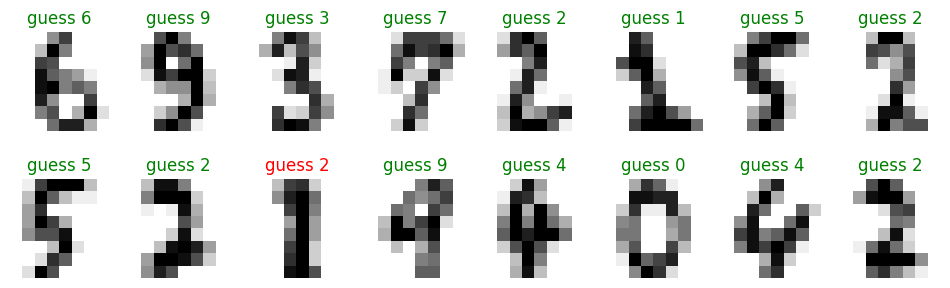

In [69]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r")
    color = "green" if guesses[i] == y_test[i] else "red"
    ax.set_title(f"guess {guesses[i]}", color=color)
    ax.axis("off")
plt.show()

## Step 8: Look at the learned filters

We asked for **16 filters**, so here are 16 small 3×3 pictures, one per pattern finder.
They started **random**. Training changed them. Many now look like small edge finders, each for a different direction. That is why we wanted more than one.

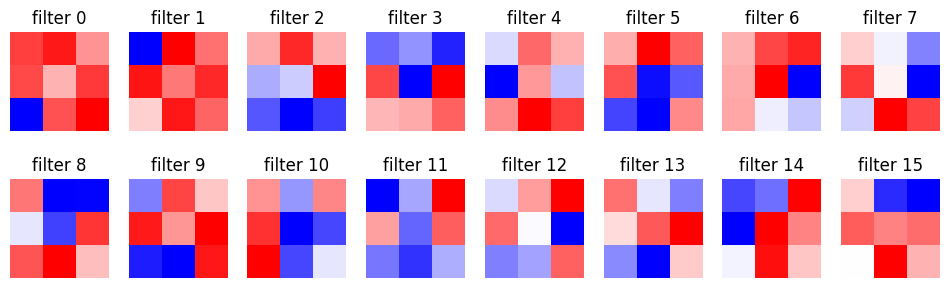

In [70]:
filters = model.conv.weight.detach()[:, 0]          # our 16 learned filters, each 3×3

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(filters[i], cmap="bwr")               # red = +, blue = −
    ax.set_title(f"filter {i}")
    ax.axis("off")
plt.show()

## ✅ Complete code (Class Problem 2)

All the steps in one cell. You can run this cell alone.

In [71]:
import torch
from torch import nn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

# 1. load
digits = load_digits()
X = digits.data / 16
y = digits.target

# 2. split 60 / 20 / 20
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=42)

# 3. tensors as pictures (pictures, 1, 8, 8)
def to_pictures(a):
    return torch.tensor(a, dtype=torch.float32).reshape(-1, 1, 8, 8)

X_train_t, X_val_t, X_test_t = to_pictures(X_train), to_pictures(X_val), to_pictures(X_test)
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)

# 4. the CNN
class CNN(nn.Module):
    def __init__(self, n_filters, n_hidden, n_outputs):
        super().__init__()
        self.conv = nn.Conv2d(1, n_filters, 3)            # 8×8 → 6×6, one map per filter
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2)                       # 6×6 → 3×3
        self.flatten = nn.Flatten()
        self.hidden = nn.Linear(n_filters * 3 * 3, n_hidden)
        self.output = nn.Linear(n_hidden, n_outputs)

    def forward(self, x):
        x = self.pool(self.relu(self.conv(x)))
        x = self.flatten(x)
        return self.output(self.relu(self.hidden(x)))

# 5. train
torch.manual_seed(42)
model = CNN(n_filters=16, n_hidden=32, n_outputs=10)   # 16 filters = 16 pattern finders (our choice, enough for 8×8)
loss_fn = nn.CrossEntropyLoss()                           # softmax is inside
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
for epoch in range(100):
    loss = loss_fn(model(X_train_t), y_train_t)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

# 6. accuracy on test
with torch.no_grad():
    guesses = model(X_test_t).argmax(dim=1).numpy()
print(f"Accuracy: {(guesses == y_test).mean():.1%}")

Accuracy: 97.5%


### Key takeaways

- **Two size rules:** 3×3 conv → **minus 2**. 2×2 pool → **divide by 2**.
- **We choose:** filter size, number of filters, pool size, number of blocks.
- **The model learns:** the numbers inside the filters and the dense weights.
- **Automatic:** every size in between. In PyTorch we still type the flatten size (144).
- **CrossEntropyLoss** has softmax inside → no softmax layer.

---
# 🏠 Home Problem

Do the **same steps** alone. Bring your answers to the next class.

**Part 1: a horizontal stroke**, like the top bar of a "7":

```
0 0 0 0 0 0
0 0 0 0 0 0
9 9 9 9 9 9
9 9 9 9 9 9
0 0 0 0 0 0
0 0 0 0 0 0
```

1. Make this 6×6 image as a tensor and show it.
2. Use the **horizontal** filter `filter_h` (top −1, middle 0, bottom +1).
3. Convolution with `nn.Conv2d` → print the 4×4 feature map.
4. ReLU → max pooling 2×2 → flatten. Print each result.
5. In words: what does the pooled 2×2 map tell you?

**Part 2: more filters**

6. Train the digits CNN with **32 filters** (`CNN(32, 32, 10)`). What number goes in the first `nn.Linear`?
7. Compare the test accuracy with 16 filters. Which is better?